<a href="https://colab.research.google.com/github/maryslopes/AI-Data-Handling/blob/M3-project/AI%20model%20selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Connecting to GCS
The project and bucket name should be in an enviromental variable

In [5]:
# ============================================
# CELL 1 - Import libraries and load dataset
# ============================================

import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [11]:
# --- GCP Configuration ---
PROJECT_ID = "equipment-failure-20122724"
BUCKET_NAME = "equipment-failure-20122724"

auth.authenticate_user()

In [12]:

# Reproducibility
RANDOM_STATE = 42

# Google Cloud Storage file path
FILE_PATH = (
    "gs://equipment-failure-20122724/"
    "processed/Equipment-Failure-clean.csv"
)

# Load dataset
df = pd.read_csv(FILE_PATH)

print(f"Dataset shape: {df.shape}")
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (10000, 15)

Columns:
['UDI', 'product_id', 'type', 'air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'split']


,UDI,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,TWF,HDF,PWF,OSF,RNF,split
0,4059,M18918,M,302.0,310.9,1456,47.2,54,0,0,0,0,0,0,train
1,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1,train
2,6896,M21755,M,301.0,311.6,1357,45.6,137,0,0,0,0,0,0,train
3,9864,L57043,L,298.9,309.8,1411,56.3,84,0,0,0,0,0,0,train
4,8712,L55891,L,297.1,308.5,1733,28.7,50,0,0,0,0,0,0,train


# Validation

In [18]:
print("Missing values:")
print(df.isnull().sum())

print("\nDataset info:")
df.info()

Missing values:
UDI                      0
product_id               0
type                     0
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
machine_failure          0
TWF                      0
HDF                      0
PWF                      0
OSF                      0
RNF                      0
split                    0
dtype: int64

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   UDI                    10000 non-null  int64  
 1   product_id             10000 non-null  object 
 2   type                   10000 non-null  object 
 3   air_temperature_k      10000 non-null  float64
 4   process_temperature_k  10000 non-null  float64
 5   rotational_speed_rpm   10000 non-null  int64  
 6   torque_nm             

### Model Hyperparameter Configuration

In [37]:
# ============================================
# Model Hyperparameter Configuration
# ============================================

# Reproducibility
RANDOM_STATE = 42

# --------------------------------------------
# SVM Hyperparameters
# --------------------------------------------
SVM_RANDOM_STATE = RANDOM_STATE
SVM_MAX_ITER = 2000

# Optional extra parameters if using SVC()
SVM_KERNEL = "rbf"
SVM_C = 1.0
SVM_GAMMA = "scale"

# --------------------------------------------
# PyTorch Neural Network Hyperparameters
# --------------------------------------------

# Number of features after preprocessing
NN_INPUT_SIZE = 7

# Hidden layer size
NN_HIDDEN_SIZE = 128

# Training parameters
NN_EPOCHS = 50
NN_BATCH_SIZE = 32
NN_LEARNING_RATE = 0.001

NN_RANDOM_STATE = RANDOM_STATE

# --------------------------------------------
# Device Selection
# --------------------------------------------
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {DEVICE}")
print(f"Input features: {NN_INPUT_SIZE}")

Using device: cuda
Input features: 7


### Load Data, Train and Compare Models

In [38]:
# Set random seeds for reproducibility
torch.manual_seed(NN_RANDOM_STATE)
np.random.seed(NN_RANDOM_STATE)

In [39]:
# Load the Equipment Failure dataset splits from GCS sharded folder
train_url = f"gs://{BUCKET_NAME}/sharded/train.csv"
dev_url = f"gs://{BUCKET_NAME}/sharded/dev.csv"
test_url = f"gs://{BUCKET_NAME}/sharded/test.csv"

# Reading the files using pandas
df_train = pd.read_csv(train_url)
df_dev = pd.read_csv(dev_url)
df_test = pd.read_csv(test_url)

print(f"Loaded train shape: {df_train.shape}, dev shape: {df_dev.shape}, test shape: {df_test.shape}")

Loaded train shape: (8000, 15), dev shape: (1000, 15), test shape: (1000, 15)


In [40]:
# Preparing features
features = ['Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]']

# Helper function to process each dataset split consistently
def preprocess_split(df_split):
    df_processed = df_split[features].copy()

    # One-hot encode machine type
    df_processed = pd.get_dummies(
        df_processed,
        columns=['Type'],
        drop_first=True
    )

    return df_processed

In [41]:
# Prepare features for Train and Dev datasets

X_train = preprocess_split(df_train)
y_train = df_train["Machine failure"]

X_test = preprocess_split(df_dev)
y_test = df_dev["Machine failure"]

# Ensure same columns
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (8000, 7)
Testing shape: (1000, 7)


In [42]:
print(X_train.columns.tolist())

['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']


In [45]:
#Feature Normalization
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# AI training

In [59]:
# Core libraries
import numpy as np
import pandas as pd
import time

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    TensorDataset,
    DataLoader)

# Scikit-learn
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [60]:
# Define PyTorch MLP Model Architecture
class EquipmentFailureMLP(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(EquipmentFailureMLP, self).__init__()
        self.network = nn.Sequential(
    nn.Linear(input_size, hidden_size),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(hidden_size, hidden_size),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(hidden_size, hidden_size),
    nn.ReLU(),

    nn.Linear(hidden_size, 1),
    nn.Sigmoid()
)

    def forward(self, x):
        return self.network(x)

 # Helper function to train and evaluate PyTorch model with timing

def train_and_eval_pytorch(X_tr, y_tr, X_te, y_te, device):

    start_time = time.time()

    # Convert data to tensors
    X_tr_t = torch.FloatTensor(
        np.array(X_tr).astype(np.float32)
    ).to(device)

    y_tr_t = torch.FloatTensor(
        np.array(y_tr).astype(np.float32)
    ).unsqueeze(1).to(device)

    X_te_t = torch.FloatTensor(
        np.array(X_te).astype(np.float32)
    ).to(device)

    dataset = TensorDataset(X_tr_t, y_tr_t)

    loader = DataLoader(
        dataset,
        batch_size=NN_BATCH_SIZE,
        shuffle=True
    )

    # Instantiate model
    model = EquipmentFailureMLP(
        X_tr.shape[1],
        NN_HIDDEN_SIZE
    ).to(device)

    criterion = nn.BCELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=NN_LEARNING_RATE
    )

    loss_history = []

    # Training loop
    model.train()

    for epoch in range(NN_EPOCHS):

        epoch_loss = 0.0

        for batch_x, batch_y in loader:

            optimizer.zero_grad()

            outputs = model(batch_x)

            loss = criterion(
                outputs,
                batch_y
            )

            loss.backward()

            optimizer.step()

            epoch_loss += (
                loss.item() *
                batch_x.size(0)
            )

        loss_history.append(
            epoch_loss / len(X_tr)
        )

    # Evaluation
    model.eval()

    with torch.no_grad():

        predictions = model(X_te_t)

        predictions = (
            predictions.cpu()
            .numpy()
            > 0.5
        ).astype(int)

        acc = accuracy_score(
            y_te,
            predictions
        )

    duration = time.time() - start_time

    return (acc,loss_history,model,duration)



# Define classic SVM (Unscaled vs Scaled)
svm_unscaled = SVC(
    kernel=SVM_KERNEL,
    C=SVM_C,
    gamma=SVM_GAMMA,
    random_state=SVM_RANDOM_STATE,
    max_iter=SVM_MAX_ITER,
    class_weight="balanced"
)

svm_scaled = SVC(
    kernel=SVM_KERNEL,
    C=SVM_C,
    gamma=SVM_GAMMA,
    random_state=SVM_RANDOM_STATE,
    max_iter=SVM_MAX_ITER,
    class_weight="balanced"
)

# 5. Train and Evaluate WITHOUT Normalization
print("=== WITHOUT FEATURE NORMALIZATION ===")
start_svm = time.time()
svm_unscaled.fit(X_train, y_train)
duration_svm_unscaled = time.time() - start_svm
y_pred_svm_unscaled = svm_unscaled.predict(X_test)
acc_svm_unscaled = accuracy_score(y_test, y_pred_svm_unscaled)
print(f"SVM Accuracy (Unscaled): {acc_svm_unscaled:.4f} (Took {duration_svm_unscaled:.4f} seconds)")

acc_nn_unscaled, loss_history_unscaled, nn_unscaled, duration_nn_unscaled = train_and_eval_pytorch(
    X_train, y_train, X_test, y_test, DEVICE
)
print(f"NN Accuracy (Unscaled):  {acc_nn_unscaled:.4f} (Took {duration_nn_unscaled:.4f} seconds)")

# 6. Train and Evaluate WITH Normalization
print("\n=== WITH FEATURE NORMALIZATION ===")
start_svm_scaled = time.time()
svm_scaled.fit(X_train_scaled, y_train)
duration_svm_scaled = time.time() - start_svm_scaled
y_pred_svm_scaled = svm_scaled.predict(X_test_scaled)
acc_svm_scaled = accuracy_score(y_test, y_pred_svm_scaled)
print(f"SVM Accuracy (Scaled):   {acc_svm_scaled:.4f} (Took {duration_svm_scaled:.4f} seconds)")

acc_nn_scaled, loss_history_scaled, nn_scaled, duration_nn_scaled = train_and_eval_pytorch(
    X_train_scaled, y_train, X_test_scaled, y_test, DEVICE
)
print(f"NN Accuracy (Scaled):    {acc_nn_scaled:.4f} (Took {duration_nn_scaled:.4f} seconds)")

=== WITHOUT FEATURE NORMALIZATION ===


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVM Accuracy (Unscaled): 0.0340 (Took 0.5906 seconds)
NN Accuracy (Unscaled):  0.9660 (Took 33.4541 seconds)

=== WITH FEATURE NORMALIZATION ===


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVM Accuracy (Scaled):   0.9180 (Took 0.8717 seconds)
NN Accuracy (Scaled):    0.9750 (Took 27.4825 seconds)


# Let's try with a GPU

In [61]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")
print("\n=== WITH FEATURE NORMALIZATION AND GPU ===")
acc_nn_scaled_gpu, loss_history_scaled_gpu, nn_scaled_gpu, duration_nn_scaled_gpu = train_and_eval_pytorch(
    X_train_scaled, y_train, X_test_scaled, y_test, DEVICE
)
print(f"NN Accuracy (Scaled):    {acc_nn_scaled_gpu:.4f} (Took {duration_nn_scaled_gpu:.4f} seconds)")

Using device: cuda

=== WITH FEATURE NORMALIZATION AND GPU ===
NN Accuracy (Scaled):    0.9780 (Took 27.6330 seconds)


### Demonstrating Feature Standardization (Mean = 0, Std = 1) for the Neural Network

In [62]:
from sklearn.preprocessing import MinMaxScaler
import time

# 1. Initialize the MinMaxScaler
min_max_scaler = MinMaxScaler()

# 2. Fit and transform the features to [0, 1]
X_train_normalized = min_max_scaler.fit_transform(X_train)
X_test_normalized = min_max_scaler.transform(X_test)

# 3. Initialize model for SVM
svm_normalized = SVC(random_state=SVM_RANDOM_STATE, max_iter=SVM_MAX_ITER)
start_svm_norm = time.time()
svm_normalized.fit(X_train_normalized, y_train)
duration_svm_normalized = time.time() - start_svm_norm
acc_svm_normalized = accuracy_score(y_test, svm_normalized.predict(X_test_normalized))

# 4. Train and evaluate PyTorch NN with MinMax Normalization
acc_nn_normalized, loss_history_normalized, nn_normalized, duration_nn_normalized = train_and_eval_pytorch(
    X_train_normalized, y_train, X_test_normalized, y_test, DEVICE
)

print("=== WITH MINMAX NORMALIZATION [0, 1] ===")
print(f"SVM Accuracy (MinMax Scaled): {acc_svm_normalized:.4f} (Took {duration_svm_normalized:.4f} seconds)")
print(f"NN Accuracy (MinMax Scaled):  {acc_nn_normalized:.4f} (Took {duration_nn_normalized:.4f} seconds)")

=== WITH MINMAX NORMALIZATION [0, 1] ===
SVM Accuracy (MinMax Scaled): 0.9670 (Took 0.1730 seconds)
NN Accuracy (MinMax Scaled):  0.9730 (Took 27.8635 seconds)


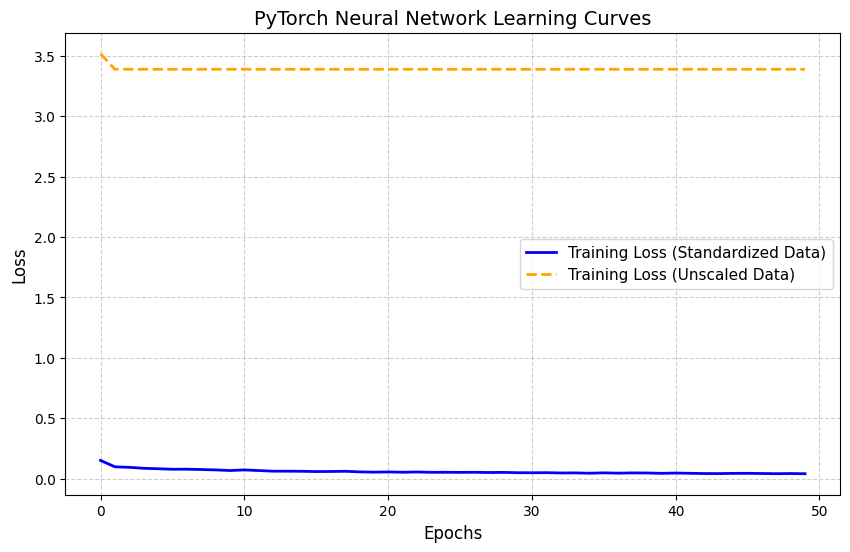

In [63]:
import matplotlib.pyplot as plt

# Plotting the loss curve for the PyTorch Neural Network
plt.figure(figsize=(10, 6))
if 'loss_history_scaled' in locals():
    plt.plot(loss_history_scaled_gpu, label='Training Loss (Standardized Data)', color='blue', linewidth=2)

if 'loss_history_unscaled' in locals():
    plt.plot(loss_history_unscaled, label='Training Loss (Unscaled Data)', color='orange', linestyle='--', linewidth=2)

plt.title('PyTorch Neural Network Learning Curves', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

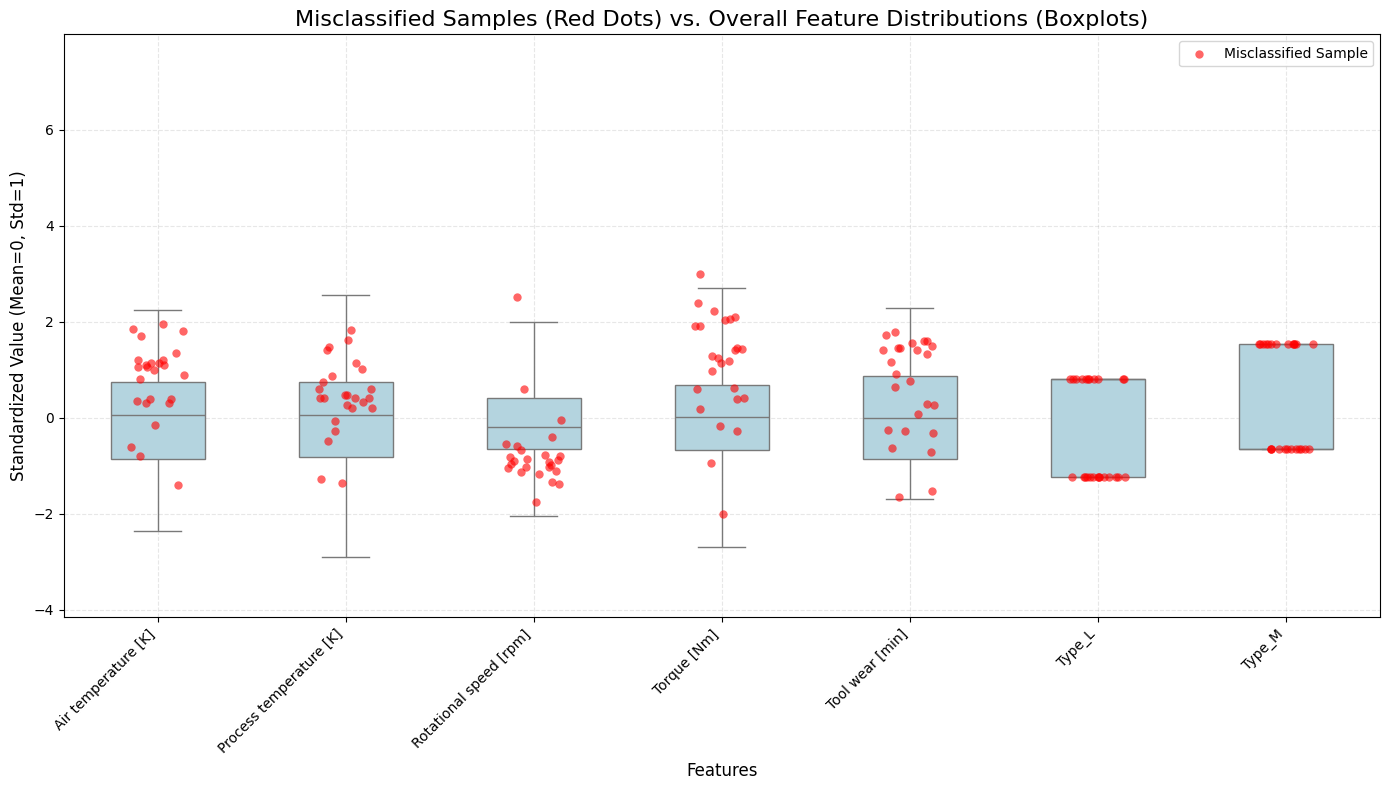

Total Test Samples: 1000
Misclassified Samples plotted as red dots: 25


In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch

# 1. Get predictions from the scaled PyTorch model
active_model = nn_scaled if 'nn_scaled' in locals() else nn_scaled_gpu
active_model.eval()

model_device = next(active_model.parameters()).device
X_test_t = torch.FloatTensor(np.array(X_test_scaled).astype(np.float32)).to(model_device)

with torch.no_grad():
    preds_prob = active_model(X_test_t).cpu().numpy().flatten()
    preds = (preds_prob > 0.5).astype(int)

# 2. Identify misclassified samples
test_targets = y_test.values
misclassified_mask = (preds != test_targets)

# 3. Use scaled features for plotting so features with different scales (e.g., Age vs Fare) can be easily compared together
features_list = list(X_train.columns)

# Convert overall scaled training features back to a DataFrame for plotting distributions
df_overall_scaled = pd.DataFrame(X_train_scaled, columns=features_list)

# Get the scaled features of only the misclassified test samples
df_misclassified_scaled = pd.DataFrame(X_test_scaled[misclassified_mask], columns=features_list)

# Melt overall data for boxplot representation
overall_melted = df_overall_scaled.melt(var_name='Feature', value_name='Standardized Value')

# Melt misclassified data for scatter overlay
misclassified_melted = df_misclassified_scaled.melt(var_name='Feature', value_name='Standardized Value')

# 4. Plot distributions and misclassified points
plt.figure(figsize=(14, 8))

# Create boxplots to show the overall distribution (median, quartiles, and std/outliers)
sns.boxplot(
    x='Feature',
    y='Standardized Value',
    data=overall_melted,
    color='lightblue',
    width=0.5,
    fliersize=0  # Hide default outliers to avoid confusion with red dots
)

# Overlay individual misclassified samples as simple red dots
sns.stripplot(
    x='Feature',
    y='Standardized Value',
    data=misclassified_melted,
    color='red',
    alpha=0.6,
    size=6,
    jitter=0.15,
    label='Misclassified Sample'
)

# Adjust legend to avoid duplicate labels for points
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend([list(by_label.values())[0]], [list(by_label.keys())[0]], loc='upper right')

plt.title('Misclassified Samples (Red Dots) vs. Overall Feature Distributions (Boxplots)', fontsize=16)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Standardized Value (Mean=0, Std=1)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total Test Samples: {len(X_test_scaled)}")
print(f"Misclassified Samples plotted as red dots: {sum(misclassified_mask)}")

In [67]:
# 1. Preprocess df_test
X_eval_test = preprocess_split(df_test)
y_eval_test = df_test['Machine failure']

# 2. Scale features for standardized models
X_eval_test_scaled = scaler.transform(X_eval_test)

print(f"Test set evaluation features shape: {X_eval_test.shape}")

# 3. Evaluate Unscaled SVM
y_pred_svm_test_unscaled = svm_unscaled.predict(X_eval_test)
acc_svm_test_unscaled = accuracy_score(y_eval_test, y_pred_svm_test_unscaled)
print(f"SVM Accuracy (Unscaled) on test set: {acc_svm_test_unscaled:.4f}")

# 4. Evaluate Scaled SVM
y_pred_svm_test_scaled = svm_scaled.predict(X_eval_test_scaled)
acc_svm_test_scaled = accuracy_score(y_eval_test, y_pred_svm_test_scaled)
print(f"SVM Accuracy (Scaled) on test set:   {acc_svm_test_scaled:.4f}")

# 5. Evaluate Neural Network on the CPU/GPU with scaled data
active_model = nn_scaled if 'nn_scaled' in locals() else nn_scaled_gpu
active_model.eval()
model_device = next(active_model.parameters()).device

X_eval_test_t = torch.FloatTensor(np.array(X_eval_test_scaled).astype(np.float32)).to(model_device)
with torch.no_grad():
    predictions_prob = active_model(X_eval_test_t).cpu().numpy()
    predictions = (predictions_prob > 0.5).astype(int).flatten()
    acc_nn_test_scaled = accuracy_score(y_eval_test, predictions)

print(f"NN Accuracy (Scaled) on test set:    {acc_nn_test_scaled:.4f}")

Test set evaluation features shape: (1000, 7)
SVM Accuracy (Unscaled) on test set: 0.0340
SVM Accuracy (Scaled) on test set:   0.9170
NN Accuracy (Scaled) on test set:    0.9830
